In [1]:
import pandas as pd
import warnings
from config import DATA_DIR, OUT_DIR, INTERMEDIATE_DIR, FIG_DIR, SEED
warnings.filterwarnings('ignore')

# Load the data
df = pd.read_csv(DATA_DIR / "WA_Marketing-Campaign.csv")

# 1. Number of rows and columns
print("=== Data size ===")
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")

# 2. Data type of each column
print("\n=== Column data types ===")
print(df.dtypes)

# 3. Preview the data
print("\n=== First 5 rows ===")
print(df.head())

# 4. Missing values (count and share per column)
print("\n=== Missing value counts ===")
print(df.isnull().sum())

print("\n=== Missing value share (%) ===")
print((df.isnull().sum() / len(df) * 100).round(2))

# 5. Descriptive statistics (numeric columns)
print("\n=== Descriptive statistics ===")
print(df.describe())

# 6. Unique values of categorical columns (Promotion, MarketSize, week, ...)
print("\n=== Unique values of categorical/discrete columns ===")
for col in ['MarketID', 'MarketSize', 'Promotion', 'week']:
    print(f"\n{col}: {df[col].unique()}")
    print(df[col].value_counts().sort_index())
    
# 7. Number of fully duplicated rows    
print("=== Fully duplicated rows ===")
print(df.duplicated().sum())

=== Data size ===
Rows: 548, columns: 7

=== Column data types ===
MarketID              int64
MarketSize              str
LocationID            int64
AgeOfStore            int64
Promotion             int64
week                  int64
SalesInThousands    float64
dtype: object

=== First 5 rows ===
   MarketID MarketSize  LocationID  AgeOfStore  Promotion  week  \
0         1     Medium           1           4          3     1   
1         1     Medium           1           4          3     2   
2         1     Medium           1           4          3     3   
3         1     Medium           1           4          3     4   
4         1     Medium           2           5          2     1   

   SalesInThousands  
0             33.73  
1             35.67  
2             29.03  
3             39.25  
4             27.81  

=== Missing value counts ===
MarketID            0
MarketSize          0
LocationID          0
AgeOfStore          0
Promotion           0
week                0
Sale

In [2]:
# ===== 1. Convert Promotion to a categorical type =====
df['Promotion'] = df['Promotion'].astype('category')
print("=== Data types after conversion ===")
print(df.dtypes)

# ===== 2. Check for fully duplicated rows =====
print("\n=== Fully duplicated rows ===")
print(df.duplicated().sum())

# ===== 3. Check for duplicated LocationID + week combinations =====
print("\n=== Duplicated LocationID + week combinations ===")
dup_key = df.duplicated(subset=['LocationID', 'week'], keep=False)
print(f"Duplicated combinations: {dup_key.sum()}")
if dup_key.sum() > 0:
    print(df[dup_key].sort_values(['LocationID', 'week'], kind="stable"))

# ===== 4. Assignment consistency (one store = one Promotion) =====
print("\n=== Number of Promotion values per LocationID ===")
promo_per_location = df.groupby('LocationID')['Promotion'].nunique()
inconsistent = promo_per_location[promo_per_location > 1]
print(f"Stores assigned to more than one promotion: {len(inconsistent)}")
if len(inconsistent) > 0:
    print(inconsistent)

# ===== 5. Number of observed weeks per store (should be 4) =====
print("\n=== Distribution of observed weeks per LocationID ===")
weeks_per_location = df.groupby('LocationID')['week'].nunique()
print(weeks_per_location.value_counts())
incomplete = weeks_per_location[weeks_per_location != 4]
if len(incomplete) > 0:
    print(f"\nStores with fewer or more than 4 weeks: {len(incomplete)}")
    print(incomplete)

# ===== 6. Check whether a LocationID appears in more than one market =====
print("\n=== LocationID values spread over several markets ===")
market_per_location = df.groupby('LocationID')['MarketID'].nunique()
print((market_per_location > 1).sum(), "stores")

# ===== Record the row count before and after cleaning =====
rows_before = len(df)
print(f"\n=== Rows so far: {rows_before} (recorded as the pre-cleaning count) ===")

=== Data types after conversion ===
MarketID               int64
MarketSize               str
LocationID             int64
AgeOfStore             int64
Promotion           category
week                   int64
SalesInThousands     float64
dtype: object

=== Fully duplicated rows ===
0

=== Duplicated LocationID + week combinations ===
Duplicated combinations: 0

=== Number of Promotion values per LocationID ===
Stores assigned to more than one promotion: 0

=== Distribution of observed weeks per LocationID ===
week
4    137
Name: count, dtype: int64

=== LocationID values spread over several markets ===
0 stores

=== Rows so far: 548 (recorded as the pre-cleaning count) ===


In [3]:
df.groupby('MarketID')['LocationID'].nunique()

MarketID
1     13
2      6
3     22
4      9
5     15
6     15
7     15
8     12
9     10
10    20
Name: LocationID, dtype: int64

In [4]:
# Number of LocationID values (stores) in each MarketID
df.groupby('MarketID')['LocationID'].nunique()

# Whether MarketID and MarketSize match one to one (a market should have a single size class)
df.groupby('MarketID')['MarketSize'].nunique()

MarketID
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
Name: MarketSize, dtype: int64

In [5]:
from scipy.stats import chisquare

# ===== 1. Number of stores (LocationID) assigned to each Promotion =====
# First reduce to one Promotion per store (removes the four-fold duplication)
store_promo = df.drop_duplicates(subset='LocationID')[['LocationID', 'Promotion']]

print("=== Stores assigned to each Promotion ===")
observed = store_promo['Promotion'].value_counts().sort_index()
print(observed)

print("\n=== Share of stores per Promotion (%) ===")
print((observed / observed.sum() * 100).round(2))

# ===== 2. SRM test (chi-square goodness of fit) =====
# Null hypothesis (H0): stores were assigned evenly (1:1:1) to the three groups
n_groups = len(observed)
expected = [observed.sum() / n_groups] * n_groups

chi2, p = chisquare(f_obs=observed, f_exp=expected)
print(f"\n=== SRM test result ===")
print(f"Observed: {observed.values}")
print(f"Expected: {expected}")
print(f"chi2 = {chi2:.4f}, p-value = {p:.4f}")

if p < 0.01:
    print("-> p < 0.01: SRM suspected. Review the assignment logic and data collection")
else:
    print("-> p >= 0.01: allocation imbalance is within chance. No SRM problem")

=== Stores assigned to each Promotion ===
Promotion
1    43
2    47
3    47
Name: count, dtype: int64

=== Share of stores per Promotion (%) ===
Promotion
1    31.39
2    34.31
3    34.31
Name: count, dtype: float64

=== SRM test result ===
Observed: [43 47 47]
Expected: [np.float64(45.666666666666664), np.float64(45.666666666666664), np.float64(45.666666666666664)]
chi2 = 0.2336, p-value = 0.8898
-> p >= 0.01: allocation imbalance is within chance. No SRM problem


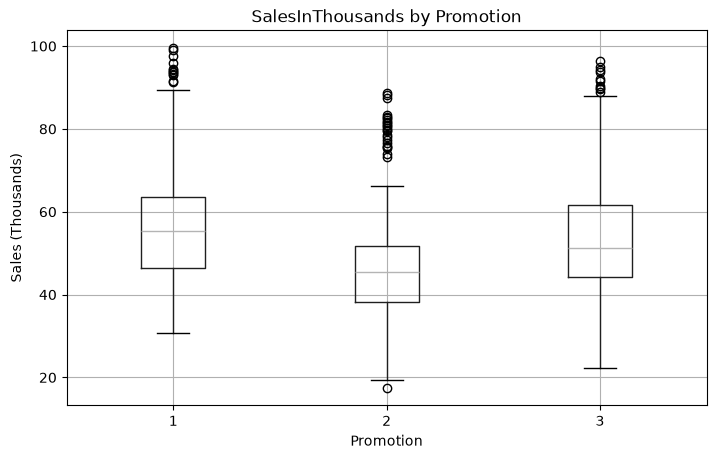

=== Outliers per group ===
Promotion
1    12
2    24
3    10
Name: SalesInThousands, dtype: int64

=== Outlier details (with the original rows) ===

Promotion 1:
     MarketID MarketSize  LocationID  AgeOfStore Promotion  week  \
83          3      Large         202           8         1     4   
108         3      Large         209           1         1     1   
109         3      Large         209           1         1     2   
110         3      Large         209           1         1     3   
111         3      Large         209           1         1     4   
114         3      Large         210          19         1     3   
128         3      Large         214           5         1     1   
130         3      Large         214           5         1     3   
144         3      Large         218           2         1     1   
154         3      Large         220           3         1     3   
160         3      Large         222           6         1     1   
163         3      Lar

In [6]:
import matplotlib.pyplot as plt

plt.rcParams['axes.unicode_minus'] = False   # keep the minus sign as a plain hyphen

# Box plot by group
fig, ax = plt.subplots(figsize=(8, 5))
df.boxplot(column='SalesInThousands', by='Promotion', ax=ax)
plt.title('SalesInThousands by Promotion')
plt.suptitle('')
plt.ylabel('Sales (Thousands)')
plt.show()

# Outlier detection by the IQR rule (per group)
def get_outliers_iqr(group):
    Q1 = group.quantile(0.25)
    Q3 = group.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return group[(group < lower) | (group > upper)]

print("=== Outliers per group ===")
outlier_counts = df.groupby('Promotion')['SalesInThousands'].apply(lambda x: len(get_outliers_iqr(x)))
print(outlier_counts)

print("\n=== Outlier details (with the original rows) ===")
for promo in df['Promotion'].cat.categories:
    sub = df[df['Promotion'] == promo]
    outliers = get_outliers_iqr(sub['SalesInThousands'])
    if len(outliers) > 0:
        print(f"\nPromotion {promo}:")
        print(df.loc[outliers.index])

In [7]:
# All four weeks of sales for store 507
print(df[df['LocationID'] == 507])

# Compare with the other stores in the same MarketID (6)
print(df[df['MarketID'] == 6].groupby('LocationID')['SalesInThousands'].mean())

     MarketID MarketSize  LocationID  AgeOfStore Promotion  week  \
284         6     Medium         507           5         2     1   
285         6     Medium         507           5         2     2   
286         6     Medium         507           5         2     3   
287         6     Medium         507           5         2     4   

     SalesInThousands  
284             38.65  
285             17.34  
286             33.14  
287             23.44  
LocationID
501    33.9125
502    32.8175
503    35.7850
504    43.3225
505    38.3400
506    31.0050
507    28.1425
508    32.3300
509    40.3150
510    29.4875
511    43.1925
512    37.8175
513    42.1900
514    39.6800
515    37.6250
Name: SalesInThousands, dtype: float64


Promotion          1          2          3
week                                      
1          58.244419  47.730213  55.776170
2          56.929535  47.582553  55.949149
3          58.774884  47.722128  54.377872
4          58.447209  46.282766  55.354681


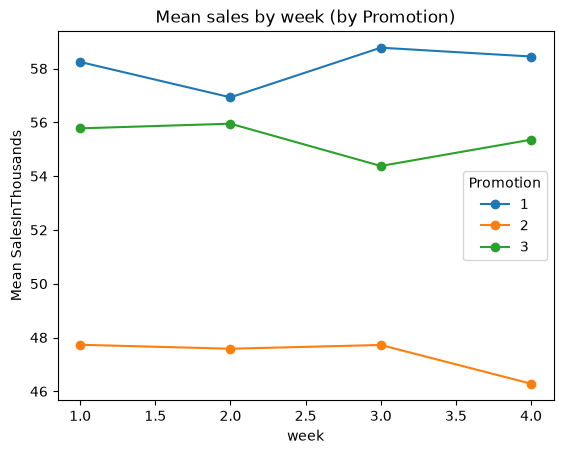


Week effect test: F=0.028, p=0.9935


In [8]:
import matplotlib.pyplot as plt

# Mean sales by week (overall and by Promotion)
week_trend = df.groupby(['Promotion', 'week'], observed=True)['SalesInThousands'].mean().unstack(level=0)
print(week_trend)

week_trend.plot(marker='o')
plt.title('Mean sales by week (by Promotion)')
plt.xlabel('week')
plt.ylabel('Mean SalesInThousands')
plt.show()

# Statistically: does week have a significant effect on sales (one-way ANOVA on week)
from scipy.stats import f_oneway
groups = [df[df['week']==w]['SalesInThousands'] for w in sorted(df['week'].unique())]
f_stat, p_val = f_oneway(*groups)
print(f"\nWeek effect test: F={f_stat:.3f}, p={p_val:.4f}")

In [9]:
# Within-store (between-week) standard deviation
within_store_std = df.groupby('LocationID')['SalesInThousands'].std().mean()
print(f"Mean within-store (between-week) standard deviation: {within_store_std:.2f}")

# Between-store standard deviation (SD of the store means)
between_store_std = df.groupby('LocationID')['SalesInThousands'].mean().std()
print(f"Between-store standard deviation: {between_store_std:.2f}")

Mean within-store (between-week) standard deviation: 4.73


Between-store standard deviation: 16.19


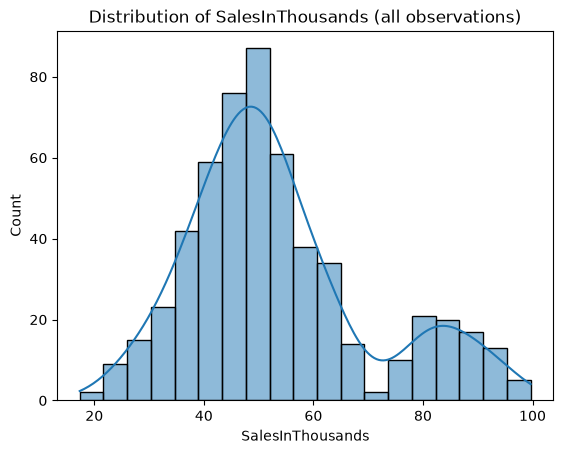

In [10]:
import seaborn as sns
sns.histplot(df['SalesInThousands'], kde=True)
plt.title('Distribution of SalesInThousands (all observations)')
plt.show()

In [11]:
store_level = df.groupby(['LocationID', 'Promotion', 'MarketID', 'MarketSize', 'AgeOfStore'], observed=True)['SalesInThousands'].mean().reset_index()
print(store_level.shape)
print(store_level.head())

(137, 6)
   LocationID Promotion  MarketID MarketSize  AgeOfStore  SalesInThousands
0           1         3         1     Medium           4           34.4200
1           2         2         1     Medium           5           29.5450
2           3         1         1     Medium          12           40.6800
3           4         2         1     Medium           1           33.7075
4           5         2         1     Medium          10           29.0025


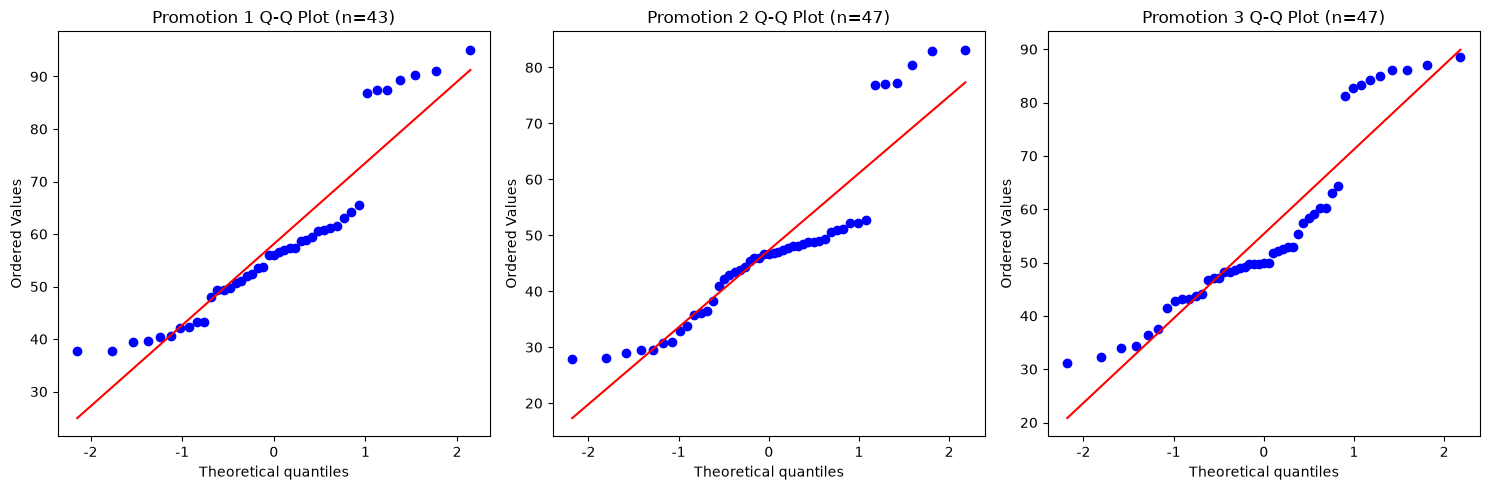

In [12]:
import scipy.stats as stats
import matplotlib.pyplot as plt

# Prepare the store-level aggregate (if not done yet)
store_level = df.groupby(['LocationID', 'Promotion', 'MarketID', 'MarketSize', 'AgeOfStore'], observed=True)['SalesInThousands'].mean().reset_index()

# ===== 1. Q-Q plot (visual check by group) =====
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, promo in enumerate(sorted(store_level['Promotion'].unique())):
    data = store_level[store_level['Promotion'] == promo]['SalesInThousands']
    stats.probplot(data, dist="norm", plot=axes[i])
    axes[i].set_title(f'Promotion {promo} Q-Q Plot (n={len(data)})')

plt.tight_layout()
plt.show()

In [13]:
print("=== Shapiro-Wilk normality test (by group) ===")
for promo in sorted(store_level['Promotion'].unique()):
    data = store_level[store_level['Promotion'] == promo]['SalesInThousands']
    stat, p = stats.shapiro(data)
    print(f"Promotion {promo}: W={stat:.4f}, p={p:.4f}")

=== Shapiro-Wilk normality test (by group) ===
Promotion 1: W=0.8684, p=0.0002
Promotion 2: W=0.8487, p=0.0000
Promotion 3: W=0.8760, p=0.0001


In [14]:
from scipy.stats import levene, f_oneway, kruskal

g1 = store_level[store_level['Promotion']==1]['SalesInThousands']
g2 = store_level[store_level['Promotion']==2]['SalesInThousands']
g3 = store_level[store_level['Promotion']==3]['SalesInThousands']

# Equal-variance test (Levene)
stat, p = levene(g1, g2, g3)
print(f"Levene test: stat={stat:.4f}, p={p:.4f}")

# ANOVA
f_stat, p_anova = f_oneway(g1, g2, g3)
print(f"\nOne-way ANOVA: F={f_stat:.4f}, p={p_anova:.4f}")

# Kruskal-Wallis (nonparametric alternative, as a cross-check)
h_stat, p_kw = kruskal(g1, g2, g3)
print(f"Kruskal-Wallis: H={h_stat:.4f}, p={p_kw:.4f}")

Levene test: stat=0.4682, p=0.6272

One-way ANOVA: F=5.8458, p=0.0037
Kruskal-Wallis: H=17.3274, p=0.0002


In [15]:
# Degrees of freedom
from scipy.stats import chi2

df_kw = 3 - 1  # number of groups - 1
alpha = 0.05

critical_value = chi2.ppf(1 - alpha, df_kw)
print(f"Degrees of freedom {df_kw}, critical value at α=0.05: {critical_value:.4f}")

Degrees of freedom 2, critical value at α=0.05: 5.9915


In [16]:
import pandas as pd
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_result = pairwise_tukeyhsd(
    endog=store_level['SalesInThousands'],
    groups=store_level['Promotion'],
    alpha=0.05
)
print(tukey_result)

tukey_df = pd.DataFrame(tukey_result._results_table.data[1:], columns=tukey_result._results_table.data[0])
tukey_df["group1"] = tukey_df["group1"].astype(int); tukey_df["group2"] = tukey_df["group2"].astype(int)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2 -10.7696  0.004 -18.5951  -2.944   True
     1      3  -2.7345 0.6862 -10.5601   5.091  False
     2      3   8.0351 0.0371   0.3854 15.6847   True
-----------------------------------------------------


In [17]:
import numpy as np

def cohens_d(x, y):
    nx, ny = len(x), len(y)
    pooled_std = np.sqrt(((nx-1)*x.std(ddof=1)**2 + (ny-1)*y.std(ddof=1)**2) / (nx+ny-2))
    return (x.mean() - y.mean()) / pooled_std

g1 = store_level[store_level['Promotion']==1]['SalesInThousands']
g2 = store_level[store_level['Promotion']==2]['SalesInThousands']
g3 = store_level[store_level['Promotion']==3]['SalesInThousands']

print(f"Promotion 1 vs 2: Cohen's d = {cohens_d(g1, g2):.3f}")
print(f"Promotion 1 vs 3: Cohen's d = {cohens_d(g1, g3):.3f}")
print(f"Promotion 2 vs 3: Cohen's d = {cohens_d(g2, g3):.3f}")

Promotion 1 vs 2: Cohen's d = 0.706
Promotion 1 vs 3: Cohen's d = 0.169
Promotion 2 vs 3: Cohen's d = -0.519


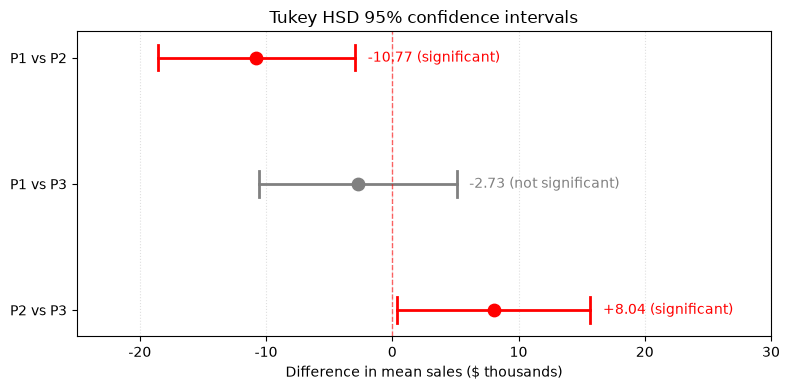

In [18]:
# Plot the confidence intervals
import matplotlib.pyplot as plt


# Tidy the Tukey HSD result (group1, group2, meandiff, lower, upper, reject)
comparisons = [(f"P{g1} vs P{g2}", md, lo, hi, bool(rej))
               for g1, g2, md, p_adj, lo, hi, rej in tukey_df.itertuples(index=False)]

fig, ax = plt.subplots(figsize=(8, 4))

for i, (label, mean, lower, upper, reject) in enumerate(comparisons):
    color = 'red' if reject else 'gray'
    # Confidence interval line
    ax.plot([lower, upper], [i, i], color=color, linewidth=2)
    # End caps
    ax.plot([lower, lower], [i-0.1, i+0.1], color=color, linewidth=2)
    ax.plot([upper, upper], [i-0.1, i+0.1], color=color, linewidth=2)
    # Mean difference point
    ax.scatter(mean, i, color=color, s=80, zorder=3)
    # Value label
    sig_text = "significant" if reject else "not significant"
    ax.text(upper + 1, i, f"{mean:+.2f} ({sig_text})", va='center', fontsize=10, color=color)

# Zero reference line
ax.axvline(0, color='red', linestyle='--', linewidth=1, alpha=0.6)

ax.set_yticks(range(len(comparisons)))
ax.set_yticklabels([c[0] for c in comparisons])
ax.set_xlabel("Difference in mean sales ($ thousands)")
ax.set_title("Tukey HSD 95% confidence intervals")
ax.set_xlim(-25, 30)
ax.invert_yaxis()  # top to bottom in order
ax.grid(axis='x', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

In [19]:
import scipy.stats as stats

g1 = store_level[store_level['Promotion']==1]['SalesInThousands']
g2 = store_level[store_level['Promotion']==2]['SalesInThousands']
g3 = store_level[store_level['Promotion']==3]['SalesInThousands']

f_stat, p_val = stats.f_oneway(g1, g2, g3)

# Eta squared
all_data = store_level['SalesInThousands']
grand_mean = all_data.mean()

ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in [g1, g2, g3])
ss_total = sum((all_data - grand_mean)**2)

eta_squared = ss_between / ss_total
print(f"η² = {eta_squared:.4f}")

η² = 0.0802


In [20]:
# Re-aggregate without store 507's outlier week (week 2, 17.34)
df_sensitivity = df[~((df['LocationID']==507) & (df['week']==2))]

store_level_sens = df_sensitivity.groupby(['LocationID','Promotion'], observed=True)['SalesInThousands'].mean().reset_index()

g1s = store_level_sens[store_level_sens['Promotion']==1]['SalesInThousands']
g2s = store_level_sens[store_level_sens['Promotion']==2]['SalesInThousands']
g3s = store_level_sens[store_level_sens['Promotion']==3]['SalesInThousands']

f_stat, p_val = stats.f_oneway(g1s, g2s, g3s)
print(f"ANOVA after excluding the outlier: F={f_stat:.4f}, p={p_val:.4f}")

# Compare with the original
f_orig, p_orig = stats.f_oneway(*[store_level[store_level["Promotion"] == k]["SalesInThousands"] for k in (1, 2, 3)])
print(f"Original ANOVA: F={f_orig:.4f}, p={p_orig:.4f}")

ANOVA after excluding the outlier: F=5.7780, p=0.0039
Original ANOVA: F=5.8458, p=0.0037


In [21]:
import pandas as pd
import matplotlib.pyplot as plt

# ===== 1. Is the Promotion × MarketSize assignment balanced? =====
print("=== Stores by Promotion x MarketSize ===")
cross_size = pd.crosstab(store_level['Promotion'], store_level['MarketSize'])
print(cross_size)

print("\n=== Row percentages (%) ===")
print((pd.crosstab(store_level['Promotion'], store_level['MarketSize'], normalize='index') * 100).round(1))

# Chi-square test of independence: are Promotion and MarketSize independent?
from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(cross_size)
print(f"\nPromotion-MarketSize independence test: chi2={chi2:.4f}, p={p:.4f}")

# ===== 2. Compare mean AgeOfStore (store age) by Promotion =====
print("\n=== Mean AgeOfStore by Promotion ===")
print(store_level.groupby('Promotion', observed=True)['AgeOfStore'].mean())

from scipy.stats import f_oneway
age1 = store_level[store_level['Promotion']==1]['AgeOfStore']
age2 = store_level[store_level['Promotion']==2]['AgeOfStore']
age3 = store_level[store_level['Promotion']==3]['AgeOfStore']
f_age, p_age = f_oneway(age1, age2, age3)
print(f"AgeOfStore difference between groups: F={f_age:.4f}, p={p_age:.4f}")

# ===== 3. Re-check the Promotion effect while adjusting for MarketSize (two-way ANOVA) =====
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('SalesInThousands ~ C(Promotion) + C(MarketSize)', data=store_level).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("\n=== Two-way ANOVA (Promotion + MarketSize) ===")
print(anova_table)

=== Stores by Promotion x MarketSize ===
MarketSize  Large  Medium  Small
Promotion                       
1              14      24      5
2              16      27      4
3              12      29      6

=== Row percentages (%) ===
MarketSize  Large  Medium  Small
Promotion                       
1            32.6    55.8   11.6
2            34.0    57.4    8.5
3            25.5    61.7   12.8

Promotion-MarketSize independence test: chi2=1.1885, p=0.8800

=== Mean AgeOfStore by Promotion ===
Promotion
1    8.279070
2    7.978723
3    9.234043
Name: AgeOfStore, dtype: float64
AgeOfStore difference between groups: F=0.4499, p=0.6387



=== Two-way ANOVA (Promotion + MarketSize) ===
                     sum_sq     df          F        PR(>F)
C(Promotion)    3244.817690    2.0  16.036196  5.828218e-07
C(MarketSize)  19450.760385    2.0  96.127499  1.735237e-26
Residual       13354.661294  132.0        NaN           NaN


In [22]:
import scipy.stats as stats
import pandas as pd

results = []

for size in ['Small', 'Medium', 'Large']:
    subset = store_level[store_level['MarketSize'] == size]
    g1 = subset[subset['Promotion']==1]['SalesInThousands']
    g2 = subset[subset['Promotion']==2]['SalesInThousands']
    g3 = subset[subset['Promotion']==3]['SalesInThousands']
    
    f_stat, p_val = stats.f_oneway(g1, g2, g3)
    results.append({'MarketSize': size, 'n': len(subset), 'F': f_stat, 'p_raw': p_val})
    print(f"{size} (n={len(subset)}): F={f_stat:.4f}, p={p_val:.4f}")

results_df = pd.DataFrame(results)
print(results_df)

Small (n=15): F=9.6436, p=0.0032
Medium (n=80): F=10.3532, p=0.0001
Large (n=42): F=5.5224, p=0.0077
  MarketSize   n          F     p_raw
0      Small  15   9.643573  0.003183
1     Medium  80  10.353195  0.000104
2      Large  42   5.522361  0.007732


In [23]:
from statsmodels.stats.multitest import multipletests

# Bonferroni correction
reject_bonf, p_bonf, _, _ = multipletests(results_df['p_raw'], alpha=0.05, method='bonferroni')

# Benjamini-Hochberg (BH) correction
reject_bh, p_bh, _, _ = multipletests(results_df['p_raw'], alpha=0.05, method='fdr_bh')

results_df['p_bonferroni'] = p_bonf
results_df['reject_bonferroni'] = reject_bonf
results_df['p_BH'] = p_bh
results_df['reject_BH'] = reject_bh

print(results_df)

  MarketSize   n          F     p_raw  p_bonferroni  reject_bonferroni  \
0      Small  15   9.643573  0.003183      0.009550               True   
1     Medium  80  10.353195  0.000104      0.000313               True   
2      Large  42   5.522361  0.007732      0.023195               True   

       p_BH  reject_BH  
0  0.004775       True  
1  0.000313       True  
2  0.007732       True  


In [24]:
n_promo2 = len(store_level[store_level['Promotion']==2])
print(f"Promotion 2 stores: {n_promo2}")

# Based on the Tukey meandiff (unit: $ thousands, weekly mean per store)
diff_p1_p2 = -tukey_df.loc[(tukey_df.group1 == 1) & (tukey_df.group2 == 2), 'meandiff'].iloc[0]
diff_p3_p2 = tukey_df.loc[(tukey_df.group1 == 2) & (tukey_df.group2 == 3), 'meandiff'].iloc[0]
weekly_loss_vs_1 = diff_p1_p2 * n_promo2
weekly_loss_vs_3 = diff_p3_p2 * n_promo2

print(f"\nEstimated weekly gap (vs Promotion 1): ${weekly_loss_vs_1:.1f}K")
print(f"Estimated weekly gap (vs Promotion 3): ${weekly_loss_vs_3:.1f}K")

# For the whole four-week campaign
print(f"\nFour-week scenario estimate (vs P1): ${weekly_loss_vs_1*4:.1f}K")
print(f"Four-week scenario estimate (vs P3): ${weekly_loss_vs_3*4:.1f}K")

Promotion 2 stores: 47

Estimated weekly gap (vs Promotion 1): $506.2K
Estimated weekly gap (vs Promotion 3): $377.6K

Four-week scenario estimate (vs P1): $2024.7K
Four-week scenario estimate (vs P3): $1510.6K


In [25]:
for size in ['Small', 'Medium', 'Large']:
    subset = store_level[store_level['MarketSize'] == size]
    mean1 = subset[subset['Promotion']==1]['SalesInThousands'].mean()
    mean3 = subset[subset['Promotion']==3]['SalesInThousands'].mean()
    print(f"{size}: P1 mean={mean1:.2f}, P3 mean={mean3:.2f}, difference (P3-P1)={mean3-mean1:.2f}")

Small: P1 mean=60.16, P3 mean=59.51, difference (P3-P1)=-0.65
Medium: P1 mean=47.67, P3 mean=45.47, difference (P3-P1)=-2.20
Large: P1 mean=75.24, P3 mean=77.20, difference (P3-P1)=1.97


In [26]:
# =====================================================================================
# Market-size-adjusted comparison. Criteria were fixed in FINAL_NUMBERS_AB.md before this cell was run.
# Unit: the 137 store-level four-week means (same as every test above).
# =====================================================================================
import numpy as np
import pandas as pd
import statsmodels.api as sm
from patsy import dmatrix
from scipy import stats
from scipy.stats import studentized_range
from statsmodels.formula.api import ols

sl = store_level.copy()
m_main = ols("SalesInThousands ~ C(Promotion) + C(MarketSize)", data=sl).fit()
m_int = ols("SalesInThousands ~ C(Promotion) * C(MarketSize)", data=sl).fit()

def type2(model):
    a = sm.stats.anova_lm(model, typ=2)
    ss_res = a.loc["Residual", "sum_sq"]
    a["partial_eta_sq"] = a["sum_sq"] / (a["sum_sq"] + ss_res)
    a.loc["Residual", "partial_eta_sq"] = np.nan
    return a.rename(columns={"PR(>F)": "p_value"}).rename_axis("term").reset_index()

a_main, a_int = type2(m_main), type2(m_int)
a_main.to_csv(OUT_DIR / "anova_main_effects.csv", index=False)
a_int.to_csv(OUT_DIR / "anova_interaction.csv", index=False)
p_inter = a_int.loc[a_int["term"] == "C(Promotion):C(MarketSize)", "p_value"].iloc[0]
print(a_main.round(6).to_string(index=False)); print(a_int.round(6).to_string(index=False))

# estimated marginal means: average the three market-size predictions with equal weights
sizes = ["Large", "Medium", "Small"]
design_info = m_main.model.data.design_info
L = {}
for k in (1, 2, 3):
    grid = pd.DataFrame({"Promotion": pd.Categorical([k] * 3, categories=[1, 2, 3]), "MarketSize": sizes})
    L[k] = np.asarray(dmatrix(design_info, grid, return_type="dataframe")).mean(axis=0)
b, cov, dfr = m_main.params.values, m_main.cov_params().values, m_main.df_resid
tcrit = stats.t.ppf(0.975, dfr)
q = studentized_range.ppf(0.95, 3, dfr)

raw_rows = []
for k in (1, 2, 3):
    g = sl.loc[sl["Promotion"] == k, "SalesInThousands"]
    em = L[k] @ b
    se = np.sqrt(L[k] @ cov @ L[k])
    half_raw = stats.t.ppf(0.975, len(g) - 1) * g.std(ddof=1) / np.sqrt(len(g))
    raw_rows.append({"promotion": k, "n_stores": len(g), "n_weekly_observations": int((df["Promotion"] == k).sum()),
                     "mean_raw": g.mean(), "ci_low_raw": g.mean() - half_raw, "ci_high_raw": g.mean() + half_raw,
                     "mean_adjusted": em, "ci_low_adjusted": em - tcrit * se, "ci_high_adjusted": em + tcrit * se})
pd.DataFrame(raw_rows).to_csv(OUT_DIR / "promo_means_ci.csv", index=False)

# unadjusted Tukey HSD (statsmodels reports group2 - group1; flip to the pairs we want)
def tk(g1, g2, sign):
    r = tukey_df[(tukey_df.group1 == g1) & (tukey_df.group2 == g2)].iloc[0]
    lo, hi = (r["lower"], r["upper"]) if sign > 0 else (-r["upper"], -r["lower"])
    return sign * r["meandiff"], lo, hi, r["p-adj"]

pairs = [("P1-P2", 1, 2, tk(1, 2, -1)), ("P3-P2", 3, 2, tk(2, 3, +1)), ("P1-P3", 1, 3, tk(1, 3, -1))]
diff_rows = []
for label, i_, j_, (td, tlo, thi, tp) in pairs:
    Ld = L[i_] - L[j_]
    d = Ld @ b
    se = np.sqrt(Ld @ cov @ Ld)
    t = d / se
    lo_t, hi_t = d - q / np.sqrt(2) * se, d + q / np.sqrt(2) * se
    if label in ("P1-P2", "P3-P2"):
        reading = ("adjusted: P2 still lower" if (lo_t > 0) else
                   "adjusted: P2 higher" if (hi_t < 0) else "adjusted: not distinguishable")
    else:
        reading = "adjusted: P1 and P3 differ" if (lo_t > 0 or hi_t < 0) else "adjusted: P1 and P3 not distinguishable"
    diff_rows.append({"comparison": label, "tukey_before_diff": td, "tukey_before_ci_low": tlo, "tukey_before_ci_high": thi,
                      "tukey_before_p": tp, "adjusted_diff": d, "adjusted_se": se,
                      "adjusted_ci_low_tukey": lo_t, "adjusted_ci_high_tukey": hi_t,
                      "adjusted_p_tukey": studentized_range.sf(abs(t) * np.sqrt(2), 3, dfr),
                      "adjusted_ci_low_unadjusted": d - tcrit * se, "adjusted_ci_high_unadjusted": d + tcrit * se,
                      "adjusted_p_unadjusted": 2 * stats.t.sf(abs(t), dfr),
                      "change_from_before": d - td, "df_resid": dfr, "interaction_p": p_inter,
                      "interaction_decision": "main-effects interpretation" if p_inter >= 0.05 else "hold main-effects interpretation",
                      "reading": reading})
pd.DataFrame(diff_rows).to_csv(OUT_DIR / "adjusted_differences.csv", index=False)
print(pd.DataFrame(diff_rows).round(4).T.to_string())

         term       sum_sq    df         F  p_value  partial_eta_sq
 C(Promotion)  3244.817690   2.0 16.036196 0.000001        0.195477
C(MarketSize) 19450.760385   2.0 96.127499 0.000000        0.592913
     Residual 13354.661294 132.0       NaN      NaN             NaN
                      term       sum_sq    df         F  p_value  partial_eta_sq
              C(Promotion)  3244.817690   2.0 16.191861 0.000001        0.201914
             C(MarketSize) 19450.760385   2.0 97.060618 0.000000        0.602634
C(Promotion):C(MarketSize)   529.184907   4.0  1.320334 0.265899        0.039625
                  Residual 12825.476387 128.0       NaN      NaN             NaN


                                                       0                            1                                        2
comparison                                         P1-P2                        P3-P2                                    P1-P3
tukey_before_diff                                10.7696                       8.0351                                   2.7345
tukey_before_ci_low                                2.944                       0.3854                                   -5.091
tukey_before_ci_high                             18.5951                      15.6847                                  10.5601
tukey_before_p                                     0.004                       0.0371                                   0.6862
adjusted_diff                                    10.7674                       9.7518                                   1.0156
adjusted_se                                       2.1244                       2.0826                          

In [27]:
# =====================================================================================
# Source CSVs for every number in the README (recomputed here so the CSVs do not depend on earlier cell variables)
# =====================================================================================
from scipy.stats import chi2, chi2_contingency, chisquare, f_oneway, kruskal, levene, shapiro
from matplotlib.cbook import boxplot_stats

PROMOS = [1, 2, 3]
SIZES = ["Small", "Medium", "Large"]
grp = {k: store_level.loc[store_level["Promotion"] == k, "SalesInThousands"] for k in PROMOS}

# data structure and quality
store_promo = df.drop_duplicates(subset="LocationID")[["LocationID", "Promotion"]]
pd.DataFrame([{
    "n_rows": len(df), "n_columns": df.shape[1], "n_stores": df["LocationID"].nunique(),
    "weeks_per_store_min": df.groupby("LocationID")["week"].nunique().min(), "weeks_per_store_max": df.groupby("LocationID")["week"].nunique().max(),
    "n_promotions": df["Promotion"].nunique(), "n_missing_cells": int(df.isna().sum().sum()), "n_duplicate_rows": int(df.duplicated().sum()),
    "n_duplicate_store_weeks": int(df.duplicated(subset=["LocationID", "week"]).sum()),
    "n_stores_with_several_promotions": int((df.groupby("LocationID")["Promotion"].nunique() > 1).sum()),
    "n_stores_in_several_markets": int((df.groupby("LocationID")["MarketID"].nunique() > 1).sum()),
}]).to_csv(OUT_DIR / "data_quality.csv", index=False)

# SRM at the store level
obs = store_promo["Promotion"].value_counts().sort_index()
chi_srm, p_srm = chisquare(f_obs=obs, f_exp=[obs.sum() / 3] * 3)
pd.DataFrame({"promotion": PROMOS, "n_stores": obs.values, "pct_stores": obs.values / obs.sum() * 100,
              "expected_n": obs.sum() / 3, "chi2": chi_srm, "p_value": p_srm}).to_csv(OUT_DIR / "srm.csv", index=False)

# outliers (IQR rule on the 548 weekly observations) and store 507
def iqr_out(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return s[(s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))]
_rows = []
for k in PROMOS:
    sub = df[df["Promotion"] == k]
    o = iqr_out(sub["SalesInThousands"]); od = sub.loc[o.index]
    _rows.append({"promotion": k, "n_weekly_observations": len(sub), "n_outliers": len(o),
                  "n_in_market_3": int((od["MarketID"] == 3).sum()), "n_in_large_markets": int((od["MarketSize"] == "Large").sum()),
                  "n_low_outliers": int((o < sub["SalesInThousands"].quantile(0.25)).sum())})
pd.DataFrame(_rows).to_csv(OUT_DIR / "outlier_counts.csv", index=False)
pd.DataFrame({"week": df.loc[df["LocationID"] == 507, "week"].values, "sales_thousands": df.loc[df["LocationID"] == 507, "SalesInThousands"].values}) \
    .to_csv(OUT_DIR / "store507_weekly.csv", index=False)
_m6 = df[df["MarketID"] == 6].groupby("LocationID")["SalesInThousands"].mean()
_others = _m6.drop(507).sort_values(ascending=False, kind="stable").values
pd.DataFrame({"store_rank_by_mean": range(1, len(_m6) + 1), "mean_sales_thousands": list(_others) + [_m6.loc[507]],
              "is_store_507": [False] * len(_others) + [True]}).to_csv(OUT_DIR / "market6_store_means.csv", index=False)

# week effect and within/between-store variation
wk_groups = [df.loc[df["week"] == w, "SalesInThousands"] for w in sorted(df["week"].unique())]
f_wk, p_wk = f_oneway(*wk_groups)
within = df.groupby("LocationID")["SalesInThousands"].std().mean()
between = df.groupby("LocationID")["SalesInThousands"].mean().std()
pd.DataFrame([{"week_effect_F": f_wk, "week_effect_p": p_wk, "within_store_sd": within, "between_store_sd": between,
               "between_over_within": between / within}]).to_csv(OUT_DIR / "week_effect_and_variation.csv", index=False)
df.groupby(["Promotion", "week"], observed=True)["SalesInThousands"].mean().rename("mean_sales_thousands").reset_index() \
    .rename(columns={"Promotion": "promotion"}).to_csv(OUT_DIR / "weekly_means_by_promotion.csv", index=False)

# assumptions and the omnibus tests
sh = [shapiro(grp[k]) for k in PROMOS]
pd.DataFrame({"promotion": PROMOS, "n_stores": [len(grp[k]) for k in PROMOS], "shapiro_W": [s.statistic for s in sh],
              "shapiro_p": [s.pvalue for s in sh]}).to_csv(OUT_DIR / "normality.csv", index=False)
lev, an, kw = levene(*grp.values()), f_oneway(*grp.values()), kruskal(*grp.values())
allv = store_level["SalesInThousands"]
eta2 = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in grp.values()) / ((allv - allv.mean()) ** 2).sum()
pd.DataFrame([{"levene_stat": lev.statistic, "levene_p": lev.pvalue, "anova_F": an.statistic, "anova_p": an.pvalue,
               "kruskal_H": kw.statistic, "kruskal_df": 2, "kruskal_p": kw.pvalue, "chi2_critical_alpha05_df2": chi2.ppf(0.95, 2),
               "eta_squared": eta2}]).to_csv(OUT_DIR / "omnibus_tests.csv", index=False)

# Tukey HSD with Cohen's d (group x vs y, as printed in the notebook)
def cohen(x, y):
    nx, ny = len(x), len(y)
    sp = np.sqrt(((nx - 1) * x.std(ddof=1) ** 2 + (ny - 1) * y.std(ddof=1) ** 2) / (nx + ny - 2))
    return (x.mean() - y.mean()) / sp
td = tukey_df.rename(columns={"p-adj": "p_adj"}).copy()
td["cohens_d_group1_minus_group2"] = [cohen(grp[a], grp[b]) for a, b in zip(td["group1"], td["group2"])]
td.to_csv(OUT_DIR / "tukey_hsd.csv", index=False)

# sensitivity to the unusual observation (store 507, week 2)
sens = df[~((df["LocationID"] == 507) & (df["week"] == 2))].groupby(["LocationID", "Promotion"], observed=True)["SalesInThousands"].mean().reset_index()
fs = f_oneway(*[sens.loc[sens["Promotion"] == k, "SalesInThousands"] for k in PROMOS])
pd.DataFrame([{"data": "original", "F": an.statistic, "p_value": an.pvalue}, {"data": "after excluding store 507 week 2", "F": fs.statistic, "p_value": fs.pvalue}]) \
    .to_csv(OUT_DIR / "sensitivity_outlier.csv", index=False)

# balance across promotion groups
ct = pd.crosstab(store_level["Promotion"], store_level["MarketSize"]).reindex(columns=SIZES)
chi_bal, p_bal, _, _ = chi2_contingency(ct)
ct.rename_axis("promotion").reset_index().assign(chi2=chi_bal, p_value=p_bal).to_csv(OUT_DIR / "balance_market_size.csv", index=False)
age = {k: store_level.loc[store_level["Promotion"] == k, "AgeOfStore"] for k in PROMOS}
fa = f_oneway(*age.values())
pd.DataFrame({"promotion": PROMOS, "mean_store_age": [age[k].mean() for k in PROMOS]}).assign(F=fa.statistic, p_value=fa.pvalue) \
    .to_csv(OUT_DIR / "balance_store_age.csv", index=False)

# segments: ANOVA per market size with Bonferroni / BH, and the means behind the segment bar chart
from statsmodels.stats.multitest import multipletests
seg = []
for s in SIZES:
    sub = store_level[store_level["MarketSize"] == s]
    r = f_oneway(*[sub.loc[sub["Promotion"] == k, "SalesInThousands"] for k in PROMOS])
    seg.append({"market_size": s, "n_stores": len(sub), "F": r.statistic, "p_raw": r.pvalue})
seg = pd.DataFrame(seg)
seg["p_bonferroni"] = multipletests(seg["p_raw"], method="bonferroni")[1]
seg["p_bh"] = multipletests(seg["p_raw"], method="fdr_bh")[1]
seg.to_csv(OUT_DIR / "segment_tests.csv", index=False)
sm_ = store_level.groupby(["MarketSize", "Promotion"], observed=True)["SalesInThousands"].agg(["mean", "size"]).reset_index()
sm_.columns = ["market_size", "promotion", "mean_sales_thousands", "n_stores"]
sm_["market_size"] = pd.Categorical(sm_["market_size"], SIZES, ordered=True)
sm_.sort_values(["market_size", "promotion"], kind="stable").to_csv(OUT_DIR / "segment_means.csv", index=False)

# the dollar scenario (47 Promotion-2 stores, 4 weeks)
n2 = int((store_promo["Promotion"] == 2).sum())
_d12 = -tukey_df.loc[(tukey_df.group1 == 1) & (tukey_df.group2 == 2), "meandiff"].iloc[0]
_d32 = tukey_df.loc[(tukey_df.group1 == 2) & (tukey_df.group2 == 3), "meandiff"].iloc[0]
pd.DataFrame([{"reference": "vs Promotion 1", "weekly_diff_per_store_thousands": _d12, "n_promotion2_stores": n2,
               "weekly_total_thousands": _d12 * n2, "weeks": 4, "four_week_total_thousands": _d12 * n2 * 4},
              {"reference": "vs Promotion 3", "weekly_diff_per_store_thousands": _d32, "n_promotion2_stores": n2,
               "weekly_total_thousands": _d32 * n2, "weeks": 4, "four_week_total_thousands": _d32 * n2 * 4}]) \
    .assign(kind="scenario estimate (Tukey differences applied to 47 stores; not a measured loss)").to_csv(OUT_DIR / "business_scenario.csv", index=False)

# data behind the Q-Q and box figures (store-level means, no store identifiers)
qq = []
for k in PROMOS:
    (osm, osr), (slope, intercept, r) = stats.probplot(grp[k], dist="norm")
    qq.append(pd.DataFrame({"promotion": k, "theoretical_quantile": osm, "ordered_value": osr, "fit_slope": slope, "fit_intercept": intercept, "fit_r": r}))
pd.concat(qq).to_csv(OUT_DIR / "qq_points.csv", index=False)
bx, fl = [], []
for k in PROMOS:
    st_ = boxplot_stats(grp[k])[0]
    bx.append({"promotion": k, "n_stores": len(grp[k]), **{key: st_[key] for key in ["q1", "med", "q3", "whislo", "whishi", "mean"]}})
    fl += [{"promotion": k, "value": v} for v in sorted(st_["fliers"])]
pd.DataFrame(bx).to_csv(OUT_DIR / "box_stats.csv", index=False)
pd.DataFrame(fl, columns=["promotion", "value"]).to_csv(OUT_DIR / "box_fliers.csv", index=False)

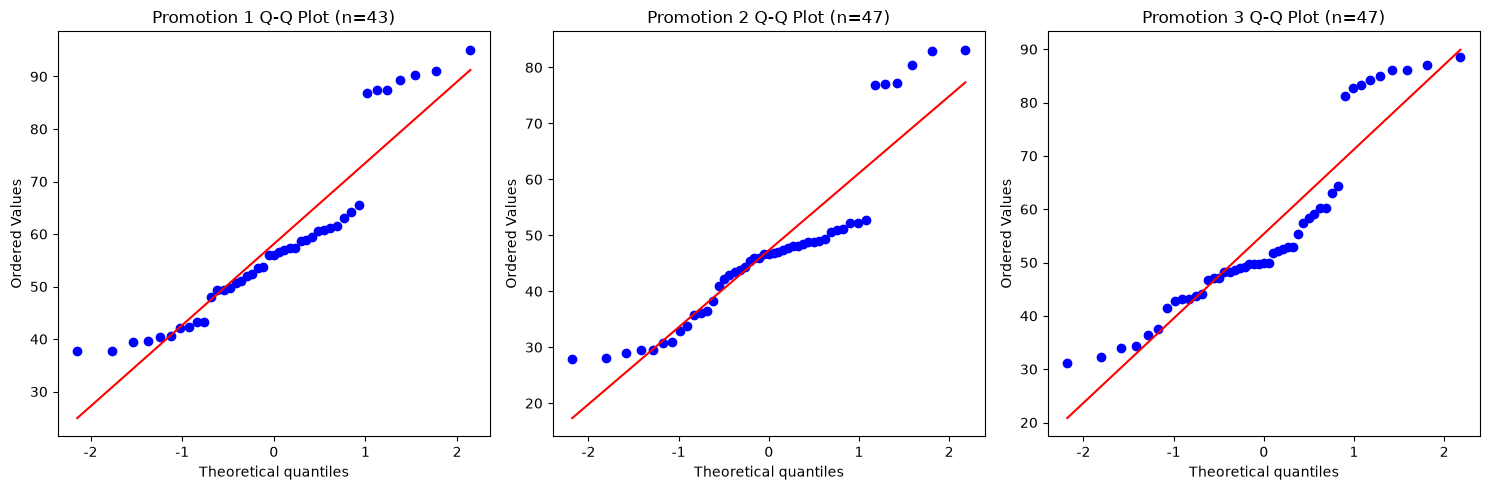

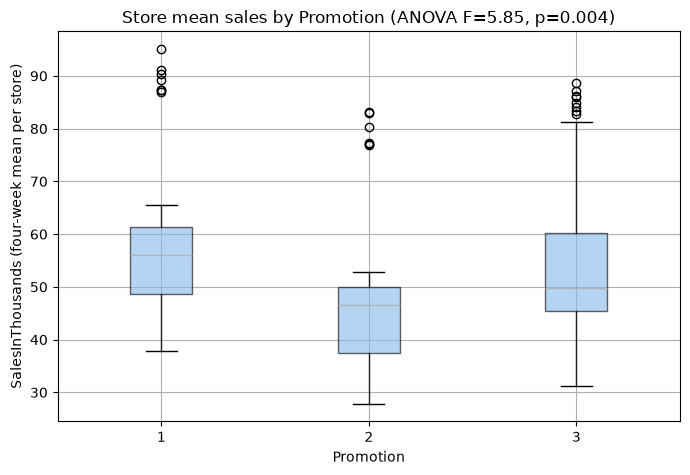

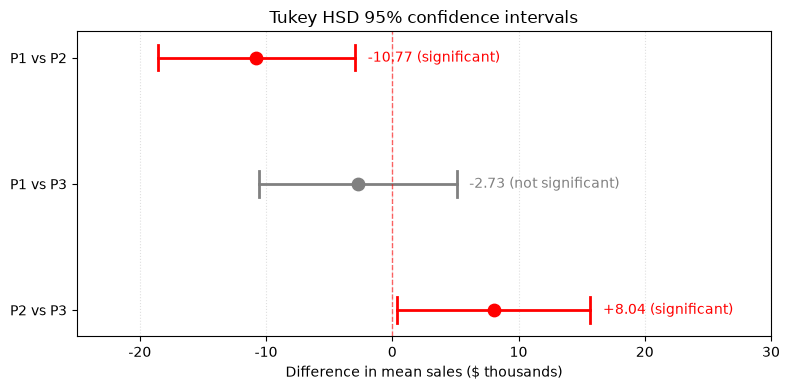

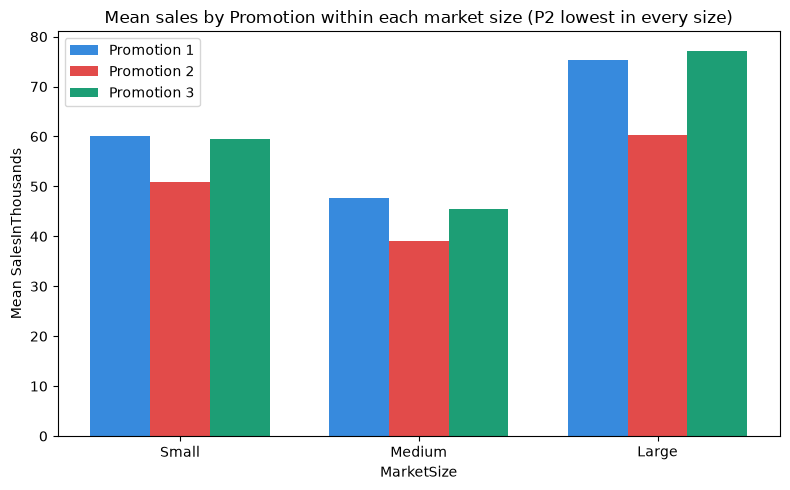

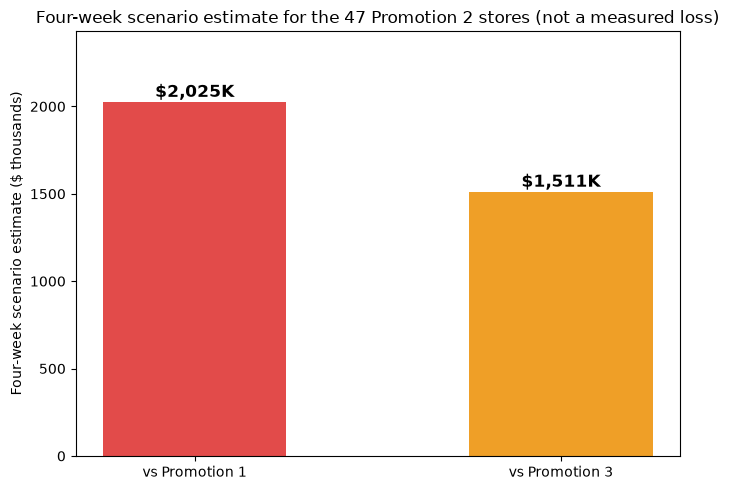

In [28]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np

plt.rcParams['axes.unicode_minus'] = False

# ============================================================
# 1. Q-Q plots (normality check, one per group)
# ============================================================
import scipy.stats as stats

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, promo in enumerate(sorted(store_level['Promotion'].unique())):
    data = store_level[store_level['Promotion'] == promo]['SalesInThousands']
    stats.probplot(data, dist="norm", plot=axes[i])
    axes[i].set_title(f'Promotion {promo} Q-Q Plot (n={len(data)})')
plt.tight_layout()
plt.show()

# ============================================================
# 2. Box plot of SalesInThousands by Promotion (for the ANOVA slide)
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5))
store_level.boxplot(column='SalesInThousands', by='Promotion', ax=ax,
                     patch_artist=True,
                     boxprops=dict(facecolor='#85B7EB', alpha=0.6))
_f_all, _p_all = stats.f_oneway(*[store_level[store_level['Promotion'] == k]['SalesInThousands'] for k in (1, 2, 3)])
ax.set_title(f'Store mean sales by Promotion (ANOVA F={_f_all:.2f}, p={_p_all:.3f})')
plt.suptitle('')
ax.set_xlabel('Promotion')
ax.set_ylabel('SalesInThousands (four-week mean per store)')
plt.tight_layout()
plt.show()

# ============================================================
# 3. Tukey HSD 95% confidence intervals (forest plot)
# ============================================================
comparisons = [(f"P{g1} vs P{g2}", md, lo, hi, bool(rej))
               for g1, g2, md, p_adj, lo, hi, rej in tukey_df.itertuples(index=False)]

fig, ax = plt.subplots(figsize=(8, 4))
for i, (label, mean, lower, upper, reject) in enumerate(comparisons):
    color = 'red' if reject else 'gray'
    ax.plot([lower, upper], [i, i], color=color, linewidth=2)
    ax.plot([lower, lower], [i-0.1, i+0.1], color=color, linewidth=2)
    ax.plot([upper, upper], [i-0.1, i+0.1], color=color, linewidth=2)
    ax.scatter(mean, i, color=color, s=80, zorder=3)
    sig_text = "significant" if reject else "not significant"
    ax.text(upper + 1, i, f"{mean:+.2f} ({sig_text})", va='center', fontsize=10, color=color)

ax.axvline(0, color='red', linestyle='--', linewidth=1, alpha=0.6)
ax.set_yticks(range(len(comparisons)))
ax.set_yticklabels([c[0] for c in comparisons])
ax.set_xlabel("Difference in mean sales ($ thousands)")
ax.set_title("Tukey HSD 95% confidence intervals")
ax.set_xlim(-25, 30)
ax.invert_yaxis()
ax.grid(axis='x', linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

# ============================================================
# 4. Mean sales by Promotion within each MarketSize (consistency and confounding check)
# ============================================================
pivot = store_level.groupby(['MarketSize', 'Promotion'], observed=True)['SalesInThousands'].mean().unstack()
pivot = pivot.reindex(['Small', 'Medium', 'Large'])  # fix the order

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(pivot.index))
width = 0.25
colors = ['#378ADD', '#E24B4A', '#1D9E75']  # P1 = blue, P2 = red (emphasizes the lowest), P3 = green

for i, promo in enumerate(pivot.columns):
    ax.bar(x + (i-1)*width, pivot[promo], width, label=f'Promotion {promo}', color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels(pivot.index)
ax.set_xlabel('MarketSize')
ax.set_ylabel('Mean SalesInThousands')
ax.set_title('Mean sales by Promotion within each market size (P2 lowest in every size)')
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================
# 5. Business impact (four-week scenario amount)
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5))
labels = ['vs Promotion 1', 'vs Promotion 3']
losses = [weekly_loss_vs_1 * 4, weekly_loss_vs_3 * 4]  # in $ thousands

bars = ax.bar(labels, losses, color=['#E24B4A', '#EF9F27'], width=0.5)
for bar, val in zip(bars, losses):
    ax.text(bar.get_x() + bar.get_width()/2, val + 30, f'${val:,.0f}K',
            ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel('Four-week scenario estimate ($ thousands)')
ax.set_title('Four-week scenario estimate for the 47 Promotion 2 stores (not a measured loss)')
ax.set_ylim(0, max(losses)*1.2)
plt.tight_layout()
plt.show()